# InfraScan Milestone 2: Crack Detection and Segmentation

This notebook trains and evaluates models on an annotated crack dataset. It is separate from the 10,000-image CCIC classification set: CCIC has crack/no-crack labels but no boxes or pixel masks. This notebook downloads Ultralytics Crack-Seg (4,029 images; train/validation/test split) and uses its polygon labels for both tasks.

**What this notebook produces:** YOLO crack boxes and masks, a small U-Net pixel mask model, held-out test metrics, example overlays, image-quality checks, and pixel-based crack geometry. Physical width is not reported because the images have no scale calibration.

In Colab, select **Runtime → Change runtime type → T4 GPU** if available, then choose **Runtime → Run all**. Allow the dataset download and training to finish.


## 1. Install the required packages

In [1]:
%pip -q install ultralytics tensorflow opencv-python-headless scikit-image pyyaml


## 2. Download and check the annotated dataset

In [2]:
import os, zipfile, urllib.request, pathlib, shutil, json, math, glob, time
from pathlib import Path
import numpy as np, cv2, yaml, matplotlib.pyplot as plt

DATA_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip"
ZIP_PATH = "/content/crack-seg.zip"
ROOT = Path("/content/crack-seg")
if not ROOT.exists():
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall("/content")

# Locate the extracted root that has the expected images/labels split folders.
possible = [p for p in Path('/content').rglob('images/train') if (p.parent.parent/'labels'/'train').exists()]
if not possible:
    raise FileNotFoundError("Could not find images/train and labels/train. Check the dataset download and extraction.")
ROOT = possible[0].parent.parent
print("Dataset folder:", ROOT)
for split in ['train','val','test']:
    imgs = list((ROOT/'images'/split).glob('*'))
    labels = list((ROOT/'labels'/split).glob('*.txt'))
    print(f"{split}: {len(imgs)} images; {len(labels)} label files")

# Create a dataset configuration for YOLO.
data_yaml = Path('/content/crack_seg_data.yaml')
data_yaml.write_text(yaml.safe_dump({'path':str(ROOT),'train':'images/train','val':'images/val','test':'images/test','names':{0:'crack'}}))
print(data_yaml.read_text())


Dataset folder: /content
train: 3717 images; 3717 label files
val: 200 images; 200 label files
test: 112 images; 112 label files
names:
  0: crack
path: /content
test: images/test
train: images/train
val: images/val



## 3. Train YOLO crack detection and segmentation

In [3]:
import torch
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else 'cpu'
print("Training device:", 'GPU' if device == 0 else 'CPU')

yolo = YOLO('yolo26n-seg.pt')
yolo_train = yolo.train(
    data=str(data_yaml), epochs=30, imgsz=640, batch=8, patience=6,
    device=device, project='/content/InfraScan_M2', name='yolo_crack',
    seed=42, plots=True, verbose=True
)
best_yolo_path = Path(yolo.trainer.best)
print("Best YOLO model:", best_yolo_path)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Training device: GPU
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crack_seg_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscr

In [11]:
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt, zipfile
figdir = Path('/content/InfraScan_M2/report_figures')
figdir.mkdir(parents=True, exist_ok=True)

# Save four held-out test examples: input, reference mask, YOLO result, and U-Net result.
pairs = image_label_pairs('test')[:4]
fig, axes = plt.subplots(len(pairs), 4, figsize=(14, 3.4 * len(pairs)))
if len(pairs) == 1:
    axes = np.array([axes])
for row, (imgp, labp) in enumerate(pairs):
    image, truth = load_pair((imgp, labp))
    yresult = best_yolo.predict(source=str(imgp), imgsz=640, device=device, verbose=False)[0]
    yolo_view = cv2.cvtColor(yresult.plot(), cv2.COLOR_BGR2RGB)
    unet_mask = unet.predict(image[None], verbose=0)[0, ..., 0] > 0.5
    axes[row,0].imshow(image); axes[row,0].set_title('Input image')
    axes[row,1].imshow(truth[...,0], cmap='gray'); axes[row,1].set_title('Reference crack mask')
    axes[row,2].imshow(yolo_view); axes[row,2].set_title('YOLO box and mask')
    axes[row,3].imshow(image); axes[row,3].imshow(unet_mask, cmap='Reds', alpha=.48); axes[row,3].set_title('U-Net overlay')
    for ax in axes[row]: ax.axis('off')
fig.tight_layout()
fig.savefig(figdir / 'heldout_predictions.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

# Deliberately inject a known label-conversion bug: omit scaling normalized polygon coordinates.
# Then use AI-style reasoning to diagnose why the faulty mask collapses near the origin.
imgp, labp = pairs[0]
original = cv2.imread(str(imgp))
h, w = original.shape[:2]
correct_mask = polygon_mask(labp, h, w)
faulty_mask = np.zeros((h,w), dtype=np.uint8)
for line in Path(labp).read_text().splitlines():
    vals = [float(v) for v in line.split()]
    if len(vals) >= 7:
        xy = np.array(vals[1:], dtype=np.float32).reshape(-1,2)
        # BUG: missing xy[:,0] *= w and xy[:,1] *= h
        cv2.fillPoly(faulty_mask, [np.round(xy).astype(np.int32)], 1)
correct_area = int(correct_mask.sum()); faulty_area = int(faulty_mask.sum())
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(correct_mask,cmap='gray'); axes[0].set_title(f'Correct mask ({correct_area} pixels)')
axes[1].imshow(faulty_mask,cmap='gray'); axes[1].set_title(f'Injected bug ({faulty_area} pixels)')
for ax in axes: ax.axis('off')
fig.suptitle('Fault diagnosis: normalized polygon coordinates were not scaled to image pixels')
fig.tight_layout()
fig.savefig(figdir / 'fault_diagnosis_example.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

diagnosis = f'''FAULT DIAGNOSIS EXAMPLE (deliberately injected preprocessing bug)
Symptom: the faulty binary target mask contains only {faulty_area} pixels; the correctly rasterized mask contains {correct_area} pixels.
Injected cause: YOLO polygon coordinates are normalized to the range 0..1, but the faulty conversion omitted multiplication by image width and height before drawing.
AI diagnosis: normalized coordinates were passed to a pixel-coordinate drawing function, so the polygon collapsed to a tiny shape near the top-left corner. This creates a severely incomplete training label and can make segmentation predictions unreliable.
Correction: multiply each x coordinate by image width and each y coordinate by image height before rounding and drawing the polygon. The notebook's polygon_mask function applies this correction.
Verification: compare the faulty and corrected masks in fault_diagnosis_example.png; the corrected mask covers the annotated crack region. This is a controlled demonstration, not a naturally occurring model failure.
'''
(figdir / 'fault_diagnosis_notes.txt').write_text(diagnosis)
zip_path = Path('/content/InfraScan_M2_Report_Figures.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for fp in figdir.iterdir(): z.write(fp, arcname=fp.name)
print(diagnosis)
print('Figures bundle:', zip_path)
from google.colab import files
files.download(str(zip_path))

Output hidden; open in https://colab.research.google.com to view.

YOLO segmentation predicts both a bounding box (detection) and a crack outline (mask). The official evaluation reports box mAP and mask mAP. We evaluate on the held-out test split below.


In [4]:
best_yolo = YOLO(str(best_yolo_path))
yolo_test = best_yolo.val(data=str(data_yaml), split='test', imgsz=640, device=device, plots=True, project='/content/InfraScan_M2', name='yolo_test')
yolo_metrics = {
    'box_precision': float(yolo_test.box.mp), 'box_recall': float(yolo_test.box.mr),
    'box_mAP50': float(yolo_test.box.map50), 'box_mAP50_95': float(yolo_test.box.map),
    'mask_precision': float(yolo_test.seg.mp), 'mask_recall': float(yolo_test.seg.mr),
    'mask_mAP50': float(yolo_test.seg.map50), 'mask_mAP50_95': float(yolo_test.seg.map)
}
print(json.dumps(yolo_metrics, indent=2))


Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 364.5±176.6 MB/s, size: 13.6 KB)
val: Scanning /content/labels/test... 112 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 112/112 1.4Kit/s 0.1s
val: New cache created: /content/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.6it/s 4.4s
                   all        112        148      0.817      0.693      0.777      0.578      0.756      0.635      0.657      0.253
Speed: 5.6ms preprocess, 8.4ms inference, 0.0ms loss, 5.0ms postprocess per image
Results saved to /content/InfraScan_M2/yolo_test
{
  "box_precision": 0.8167464112502523,
  "box_recall": 0.6926427665074832,
  "box_mAP50": 0.776748313334106,
  "box_mAP50_95": 0.577551332455822

## 4. Build pixel masks from the dataset polygons

In [5]:
# Convert each YOLO polygon label file to a binary mask. This is the target for U-Net.
IMAGE_EXTS = {'.jpg','.jpeg','.png','.bmp'}
def image_label_pairs(split):
    image_dir, label_dir = ROOT/'images'/split, ROOT/'labels'/split
    pairs=[]
    for p in sorted(image_dir.iterdir()):
        if p.suffix.lower() in IMAGE_EXTS:
            q=label_dir/(p.stem+'.txt')
            if q.exists(): pairs.append((p,q))
    return pairs

def polygon_mask(label_path, height, width):
    mask=np.zeros((height,width), dtype=np.uint8)
    for line in Path(label_path).read_text().splitlines():
        vals=[float(v) for v in line.split()]
        if len(vals) < 7: continue
        coords=np.array(vals[1:],dtype=np.float32).reshape(-1,2)
        coords[:,0]*=width; coords[:,1]*=height
        cv2.fillPoly(mask,[np.round(coords).astype(np.int32)],1)
    return mask

for split in ['train','val','test']:
    print(split, 'paired images:',len(image_label_pairs(split)))


train paired images: 3717
val paired images: 200
test paired images: 112


## 5. Train a small U-Net model

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE=256
BATCH=8

def load_pair(pair):
    img_path, label_path=pair
    image=cv2.imread(str(img_path))
    if image is None: raise ValueError(f"Cannot read {img_path}")
    image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
    h,w=image.shape[:2]
    mask=polygon_mask(label_path,h,w)
    image=cv2.resize(image,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_AREA).astype('float32')/255.0
    mask=cv2.resize(mask,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_NEAREST).astype('float32')[...,None]
    return image,mask

class CrackSequence(keras.utils.Sequence):
    def __init__(self,pairs,batch_size=8,shuffle=False):
        self.pairs=list(pairs); self.batch_size=batch_size; self.shuffle=shuffle; self.ids=np.arange(len(self.pairs)); self.on_epoch_end()
    def __len__(self): return math.ceil(len(self.ids)/self.batch_size)
    def __getitem__(self,i):
        ids=self.ids[i*self.batch_size:(i+1)*self.batch_size]
        samples=[load_pair(self.pairs[j]) for j in ids]
        return np.stack([a for a,b in samples]),np.stack([b for a,b in samples])
    def on_epoch_end(self):
        if self.shuffle: np.random.shuffle(self.ids)

def dice_loss(y_true,y_pred,smooth=1.):
    yt=tf.reshape(tf.cast(y_true,tf.float32),[-1]); yp=tf.reshape(tf.cast(y_pred,tf.float32),[-1])
    return 1.-(2.*tf.reduce_sum(yt*yp)+smooth)/(tf.reduce_sum(yt)+tf.reduce_sum(yp)+smooth)

def bce_dice(y_true,y_pred): return keras.losses.binary_crossentropy(y_true,y_pred)+dice_loss(y_true,y_pred)

def conv_block(x,filters):
    x=layers.Conv2D(filters,3,padding='same',activation='relu')(x)
    x=layers.BatchNormalization()(x)
    x=layers.Conv2D(filters,3,padding='same',activation='relu')(x)
    return layers.BatchNormalization()(x)

def build_unet():
    inp=layers.Input((IMG_SIZE,IMG_SIZE,3))
    c1=conv_block(inp,16); p1=layers.MaxPooling2D()(c1)
    c2=conv_block(p1,32); p2=layers.MaxPooling2D()(c2)
    c3=conv_block(p2,64); p3=layers.MaxPooling2D()(c3)
    c4=conv_block(p3,128); p4=layers.MaxPooling2D()(c4)
    b=conv_block(p4,256)
    u4=layers.Concatenate()([layers.UpSampling2D()(b),c4]); c5=conv_block(u4,128)
    u3=layers.Concatenate()([layers.UpSampling2D()(c5),c3]); c6=conv_block(u3,64)
    u2=layers.Concatenate()([layers.UpSampling2D()(c6),c2]); c7=conv_block(u2,32)
    u1=layers.Concatenate()([layers.UpSampling2D()(c7),c1]); c8=conv_block(u1,16)
    out=layers.Conv2D(1,1,activation='sigmoid')(c8)
    return keras.Model(inp,out)

train_seq=CrackSequence(image_label_pairs('train'),BATCH,True)
val_seq=CrackSequence(image_label_pairs('val'),BATCH,False)
test_seq=CrackSequence(image_label_pairs('test'),BATCH,False)
unet=build_unet()
unet.compile(optimizer=keras.optimizers.Adam(1e-3),loss=bce_dice)
callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True),keras.callbacks.ModelCheckpoint('/content/InfraScan_M2/unet_best.keras',save_best_only=True,monitor='val_loss')]
history=unet.fit(train_seq,validation_data=val_seq,epochs=20,callbacks=callbacks)


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


465/465 ━━━━━━━━━━━━━━━━━━━━ 122s 174ms/step - loss: 0.9101 - val_loss: 0.4385
Epoch 2/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 54s 116ms/step - loss: 0.3530 - val_loss: 0.3430
Epoch 3/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - loss: 0.3226 - val_loss: 0.3868
Epoch 4/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 53s 114ms/step - loss: 0.3116 - val_loss: 0.3320
Epoch 5/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 113ms/step - loss: 0.3075 - val_loss: 0.3071
Epoch 6/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - loss: 0.3037 - val_loss: 0.3212
Epoch 7/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - loss: 0.2998 - val_loss: 0.3196
Epoch 8/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - loss: 0.2954 - val_loss: 0.3251
Epoch 9/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - loss: 0.2925 - val_loss: 0.3189


## 6. Evaluate U-Net on the held-out test images

In [7]:
def segmentation_scores(model,seq,threshold=.5):
    intersections=unions=tp=fp=fn=0
    per_dice=[]; per_iou=[]
    for i in range(len(seq)):
        x,y=seq[i]; pred=model.predict(x,verbose=0)>.5; truth=y>.5
        for a,b in zip(pred,truth):
            a=a[...,0]; b=b[...,0]
            inter=np.logical_and(a,b).sum(); union=np.logical_or(a,b).sum()
            per_dice.append((2*inter)/(a.sum()+b.sum()+1e-7)); per_iou.append(inter/(union+1e-7))
            intersections+=inter; unions+=union
            tp+=inter; fp+=np.logical_and(a,~b).sum(); fn+=np.logical_and(~a,b).sum()
    return {'pixel_precision':float(tp/(tp+fp+1e-7)),'pixel_recall':float(tp/(tp+fn+1e-7)),
            'pixel_dice':float(2*tp/(2*tp+fp+fn+1e-7)),'pixel_IoU':float(tp/(tp+fp+fn+1e-7)),
            'mean_image_dice':float(np.mean(per_dice)),'mean_image_IoU':float(np.mean(per_iou))}

unet_metrics=segmentation_scores(unet,test_seq)
print(json.dumps(unet_metrics,indent=2))


{
  "pixel_precision": 0.7261569139787347,
  "pixel_recall": 0.7268166113774953,
  "pixel_dice": 0.7264866129162907,
  "pixel_IoU": 0.5704585599841346,
  "mean_image_dice": 0.7063695598986692,
  "mean_image_IoU": 0.5665790775093126
}


## 7. View predictions and check image quality

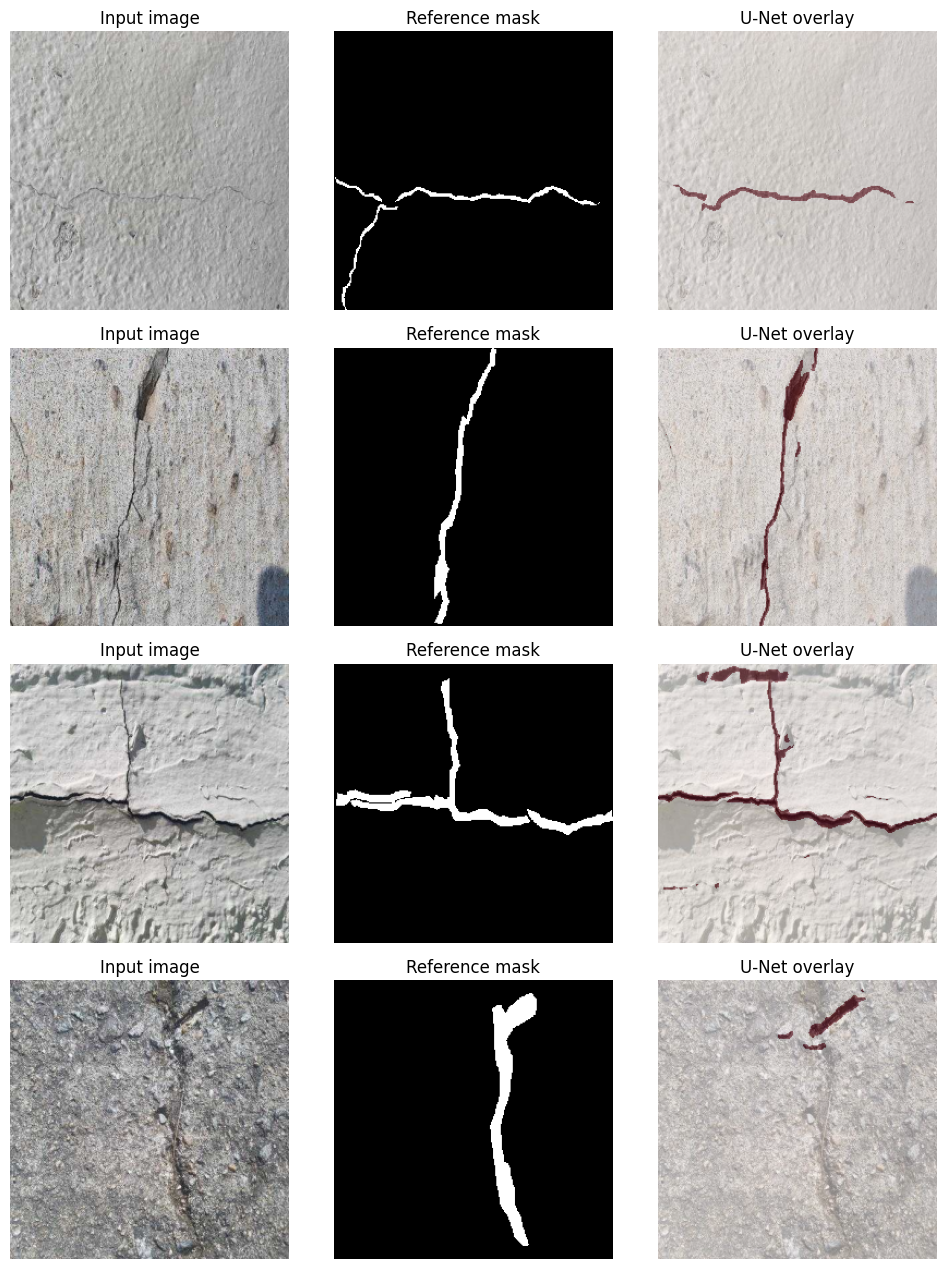

Example quality indicators: {'mean_brightness': 170.3779296875, 'brightness_std': 17.957047942931847, 'blur_score_laplacian_variance': 1102.6128437034824}
Blur score is only a simple image-quality indicator; it is not a crack metric.


In [8]:
def show_unet_examples(pairs,n=4):
    picks=pairs[:n]
    fig,axes=plt.subplots(len(picks),3,figsize=(10,3.2*len(picks)))
    if len(picks)==1: axes=np.array([axes])
    for row,(imgp,labp) in enumerate(picks):
        x,y=load_pair((imgp,labp)); pred=unet.predict(x[None],verbose=0)[0,...,0]>.5
        axes[row,0].imshow(x); axes[row,0].set_title('Input image')
        axes[row,1].imshow(y[...,0],cmap='gray'); axes[row,1].set_title('Reference mask')
        axes[row,2].imshow(x); axes[row,2].imshow(pred,cmap='Reds',alpha=.45); axes[row,2].set_title('U-Net overlay')
        for ax in axes[row]: ax.axis('off')
    plt.tight_layout(); plt.show()
show_unet_examples(image_label_pairs('test'))

def image_quality(image_path):
    im=cv2.imread(str(image_path),cv2.IMREAD_GRAYSCALE)
    return {'mean_brightness':float(im.mean()),'brightness_std':float(im.std()),'blur_score_laplacian_variance':float(cv2.Laplacian(im,cv2.CV_64F).var())}
print('Example quality indicators:',image_quality(image_label_pairs('test')[0][0]))
print('Blur score is only a simple image-quality indicator; it is not a crack metric.')


## 8. Estimate pixel geometry and save outputs

In [9]:
from skimage.morphology import skeletonize

def pixel_geometry(binary_mask):
    mask=binary_mask.astype(bool)
    area=int(mask.sum())
    if area==0: return {'crack_area_pixels':0,'skeleton_length_pixels':0,'average_width_proxy_pixels':0.0,'bounding_box_pixels':[0,0,0,0]}
    ys,xs=np.where(mask); skel=skeletonize(mask); length=int(skel.sum())
    width_proxy=float(area/max(length,1))
    return {'crack_area_pixels':area,'skeleton_length_pixels':length,'average_width_proxy_pixels':width_proxy,
            'bounding_box_pixels':[int(xs.min()),int(ys.min()),int(xs.max()+1),int(ys.max()+1)]}

# Example U-Net geometry on one held-out image. No physical size in mm is claimed.
img_path,label_path=image_label_pairs('test')[0]
x,y=load_pair((img_path,label_path)); pred=unet.predict(x[None],verbose=0)[0,...,0]>.5
print(json.dumps(pixel_geometry(pred),indent=2))

RESULTS={'dataset':str(ROOT),'device':str(device),'yolo_test':yolo_metrics,'unet_test':unet_metrics}
out=Path('/content/InfraScan_Milestone_2_Results'); out.mkdir(exist_ok=True)
(out/'metrics.json').write_text(json.dumps(RESULTS,indent=2))
unet.save(out/'unet_model.keras')
shutil.copy2(best_yolo_path,out/'best_yolo_seg.pt')
import shutil as _shutil
_shutil.make_archive('/content/InfraScan_Milestone_2_Results','zip',out)
from google.colab import files
files.download('/content/InfraScan_Milestone_2_Results.zip')
print('Results bundle downloaded. Save it and share it here so the report can include the actual measured results.')


{
  "crack_area_pixels": 1023,
  "skeleton_length_pixels": 222,
  "average_width_proxy_pixels": 4.608108108108108,
  "bounding_box_pixels": [
    14,
    141,
    235,
    165
  ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Results bundle downloaded. Save it and share it here so the report can include the actual measured results.


## What to include in the report

After the notebook finishes, use the values printed in `metrics.json`. Include YOLO box mAP/precision/recall, YOLO mask mAP, U-Net pixel Dice/IoU/precision/recall, and the example input/reference/prediction images. These scores apply to this dataset and split only. The crack-seg images include roads and walls, so they are not a substitute for testing on the project’s own concrete images. Pixel geometry is not a physical crack-width estimate without a scale reference.

Dataset and training workflow: [Ultralytics Crack-Seg dataset documentation](https://docs.ultralytics.com/datasets/segment/crack-seg); [Ultralytics instance segmentation training documentation](https://docs.ultralytics.com/tasks/segment). Cite Ultralytics and the underlying dataset attribution given in the dataset documentation.
